# **Box Cox Transform**

## $$y^{(\lambda)} = \begin{cases} \frac{y^\lambda - 1}{\lambda} & \text{if } \lambda \neq 0 \\ \ln(y) & \text{if } \lambda = 0 \end{cases}$$

### The exponent here is a variable named lambda that varies over the range **-5 to 5**, and in the process of searching, we examine the values of lambda. Finally we choose the optimal value (resulting in the best approximation to a normal distriution) for your variable.

### ***--> strictly applicable for y>0***

### This is removed by veo - johnsons transform.

# Veo- Johnson Transform

## $$y^{(\lambda)} = \begin{cases} \frac{(y + 1)^\lambda - 1}{\lambda} & \text{if } \lambda \neq 0, y \geq 0 \\ \ln(y + 1) & \text{if } \lambda = 0, y \geq 0 \\ -\frac{(-y + 1)^{2 - \lambda} - 1}{2 - \lambda} & \text{if } \lambda \neq 2, y < 0 \\ -\ln(-y + 1) & \text{if } \lambda = 2, y < 0 \end{cases}$$

### This can be applied for negative numbers too

In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [3]:
df = pd.read_csv('concrete_data.csv')

In [4]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [6]:
df.shape

(1030, 9)

In [7]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [8]:
x = df.drop(columns=['Strength'])
y = df.iloc[:, -1]

In [9]:
X_train, X_test, Y_train, Y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [10]:
#Apply linear regression without any transfomation
lr = LinearRegression()
lr.fit(X_train, Y_train)
y_pred = lr.predict(X_test)
r2_score(Y_test, y_pred)

0.627553179231485

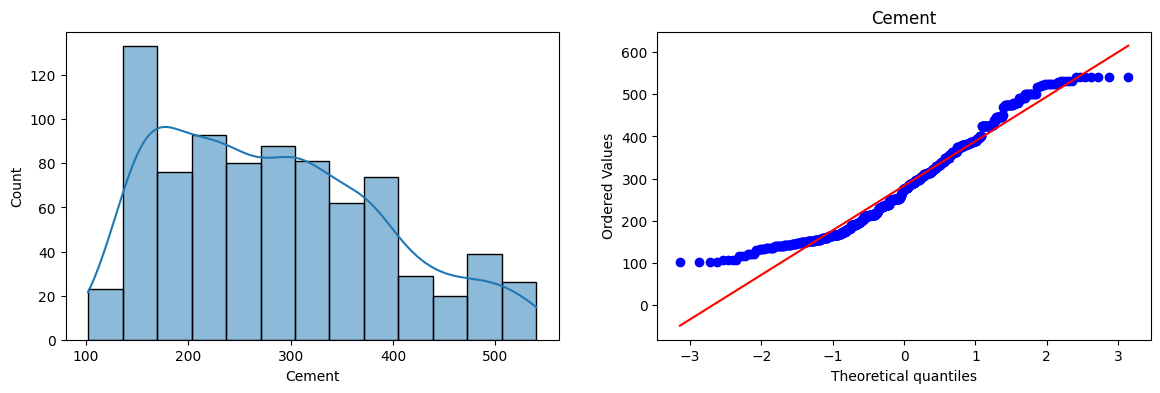

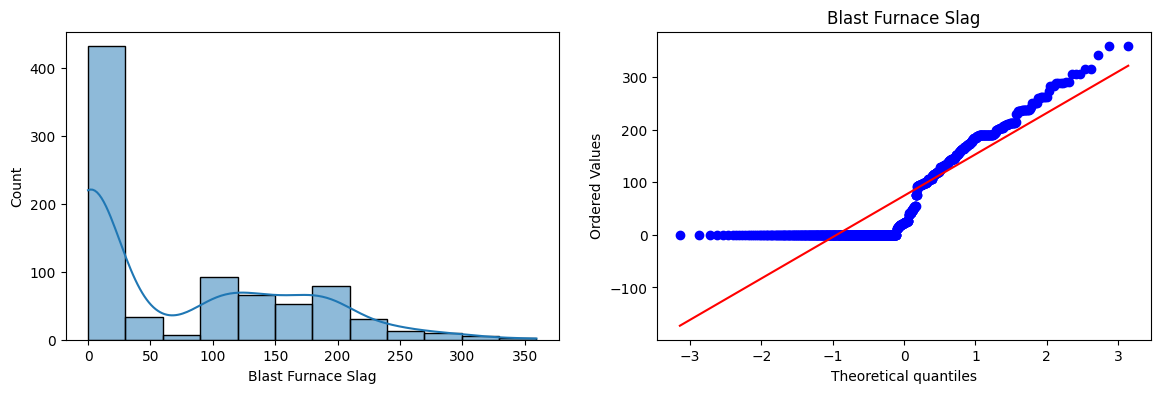

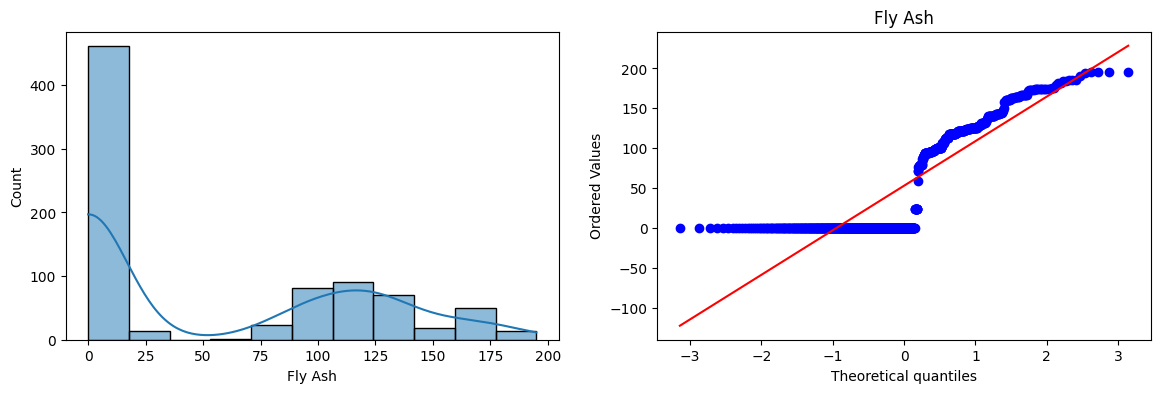

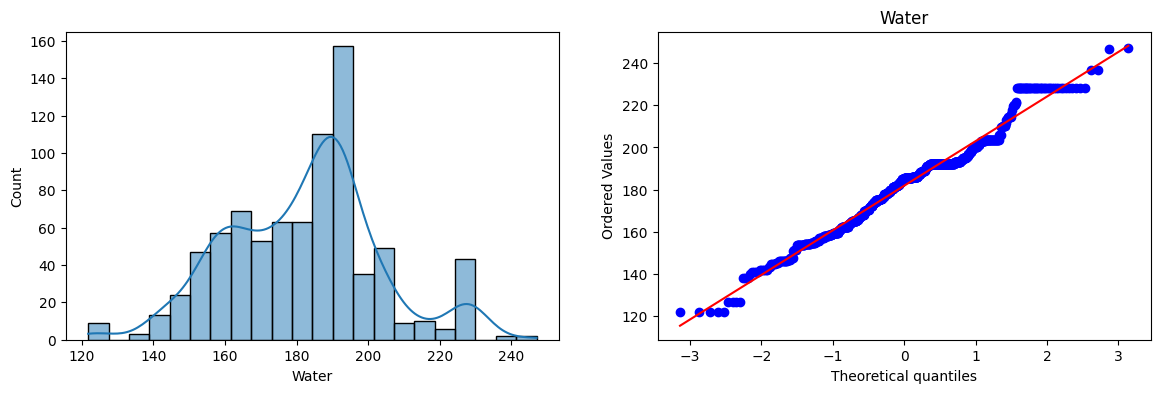

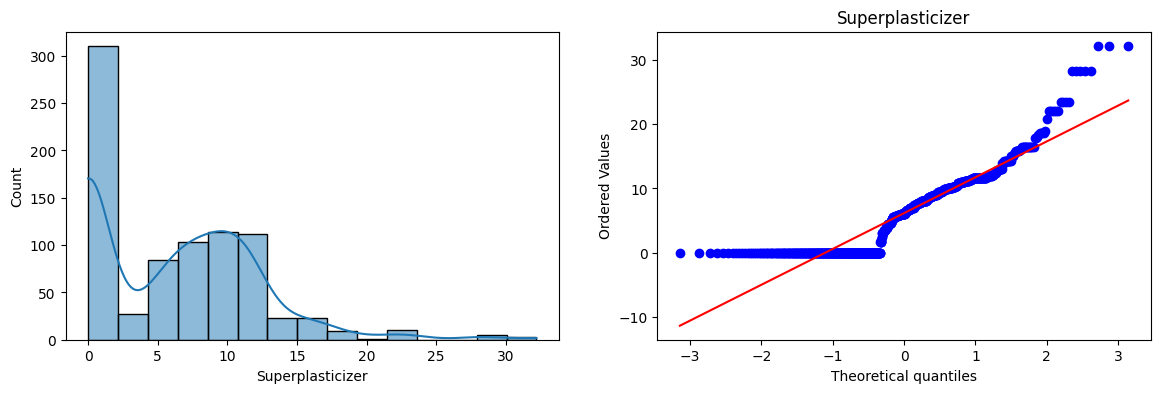

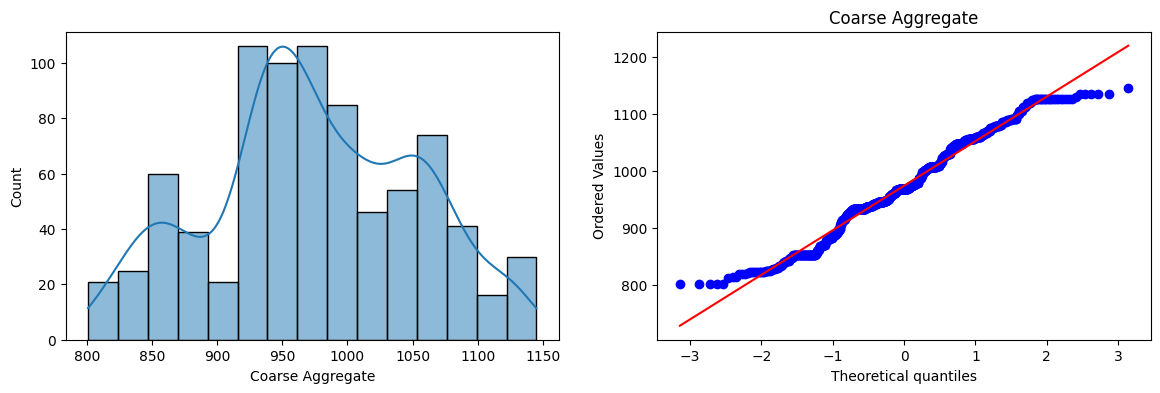

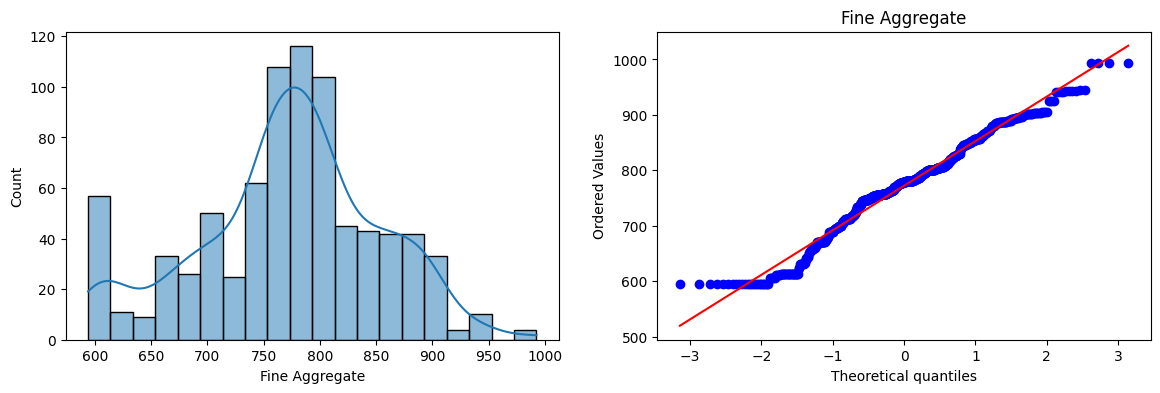

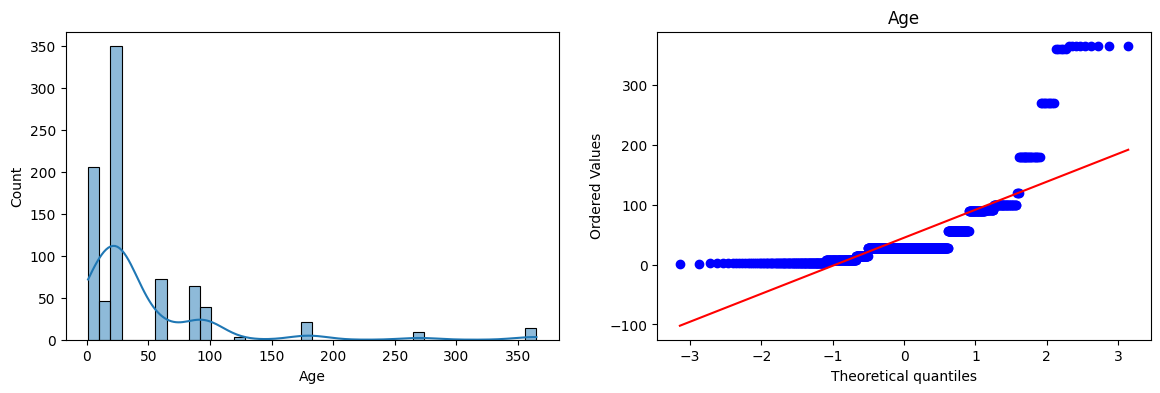

In [14]:
for col in X_train.columns:
    plt.figure(figsize = (14, 4))
    plt.subplot(121)
    sns.histplot(X_train[col], kde = True)
    plt.subplot(122)
    stats.probplot(X_train[col], dist = 'norm', plot=plt)
    plt.title(col)
    plt.show()

In [18]:
#apply box- cox transform 
pt = PowerTransformer(method = 'box-cox') #by default: veo-johnson 
X_train_transformed = pt.fit_transform(X_train + 0.000001)
X_test_transformed = pt.transform(X_test + 0.000001)
pd.DataFrame({'cols':X_train.columns, 'box_cox_lambdas':pt.lambdas_})


,cols,box_cox_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.025093
2,Fly Ash,-0.038970
3,Water,0.772682
4,Superplasticizer,0.098811
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [19]:
lr = LinearRegression()
lr.fit(X_train_transformed, Y_train)
y_pred = lr.predict(X_test_transformed)
r2_score(Y_test, y_pred)

0.8047824993092503

## Accuracy score increased from 62% to 80% !

In [23]:
pt =PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(x + 0.000001)
lr = LinearRegression()
print(np.mean(cross_val_score(lr, X_transformed, y, scoring='r2')))

0.6662950329054064


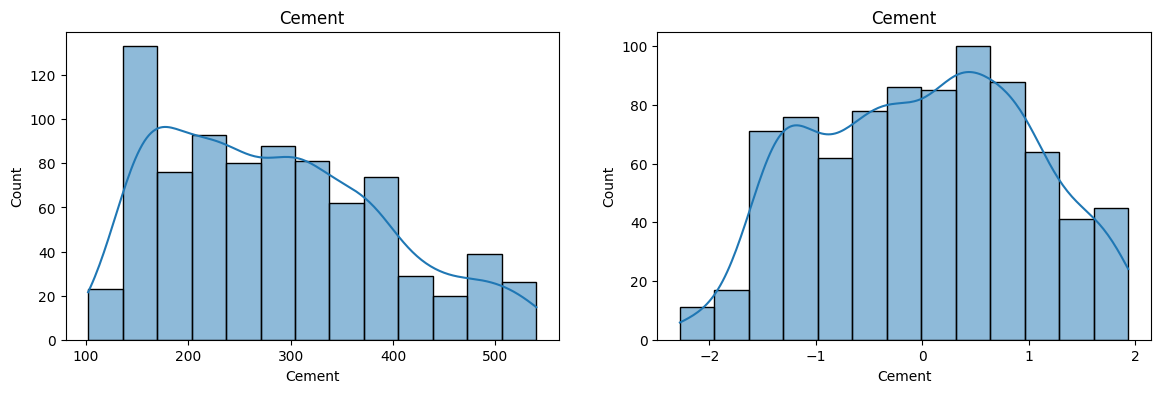

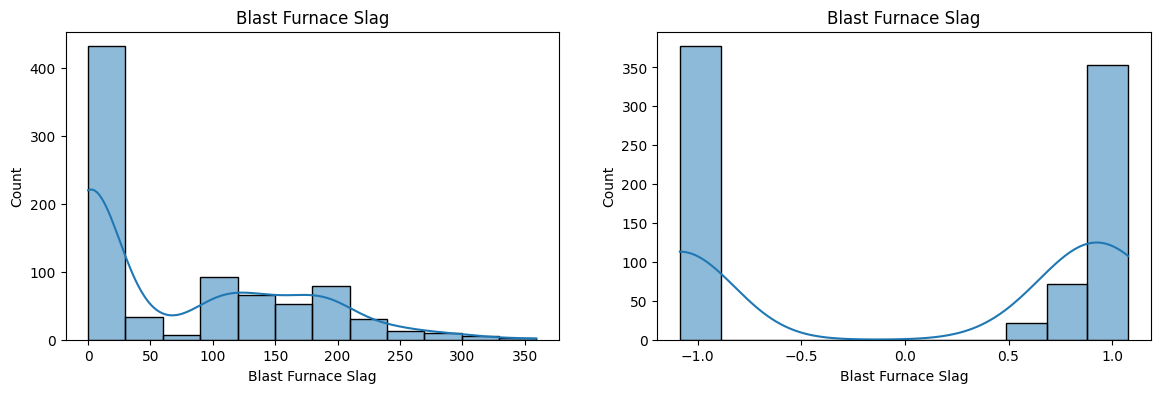

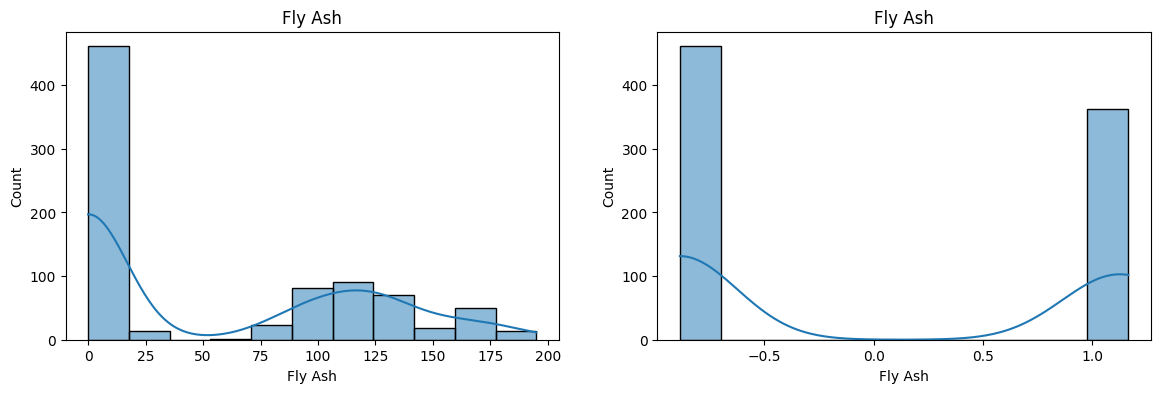

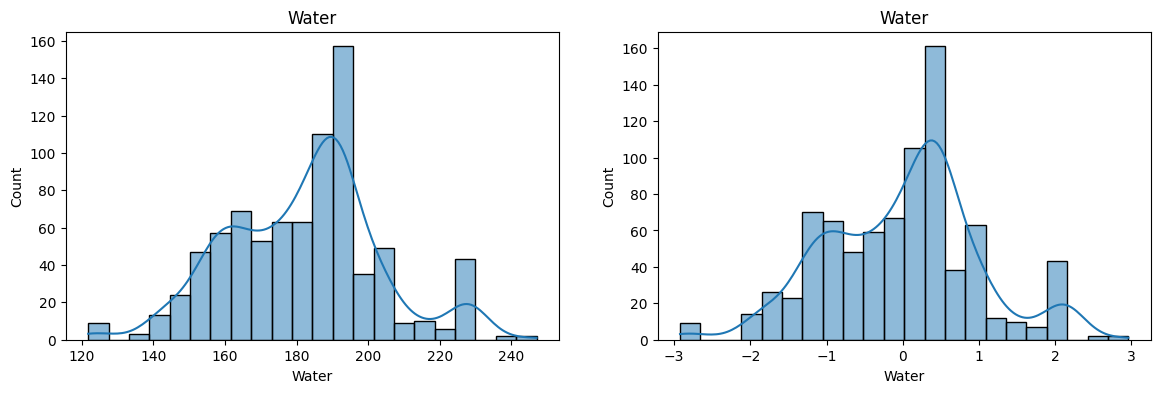

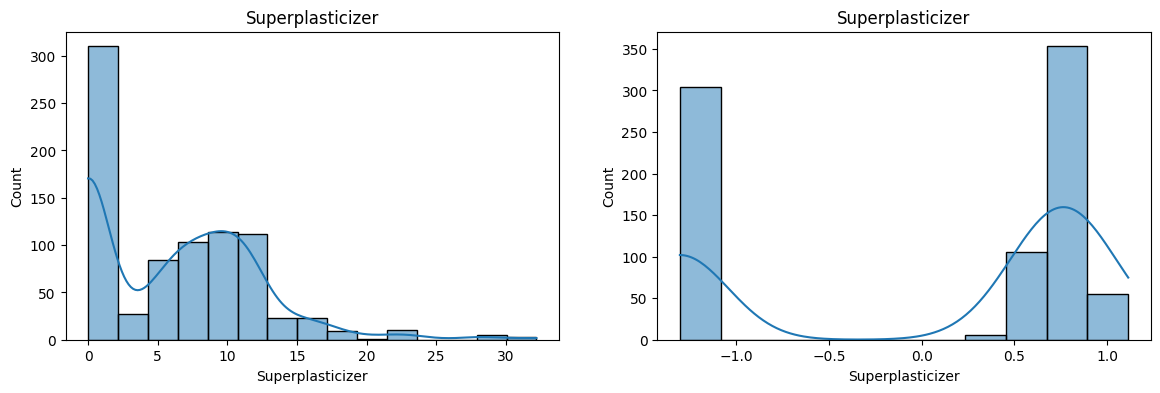

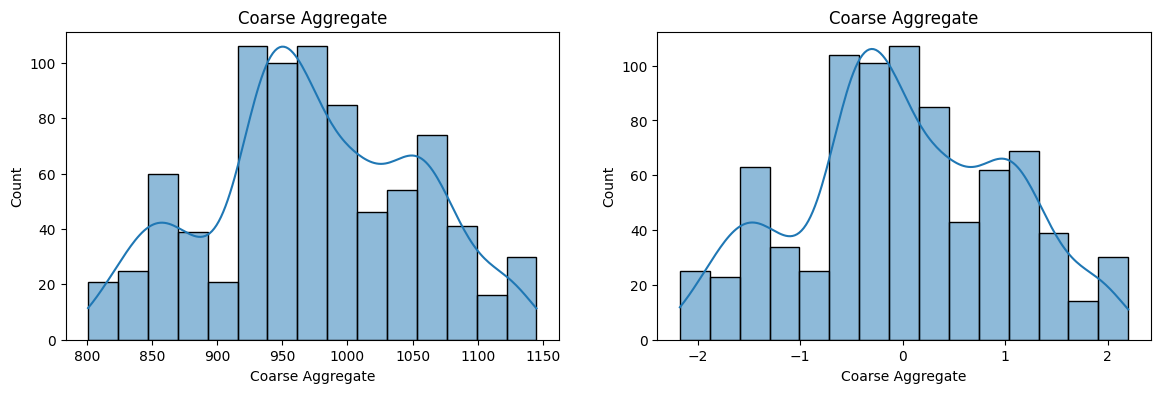

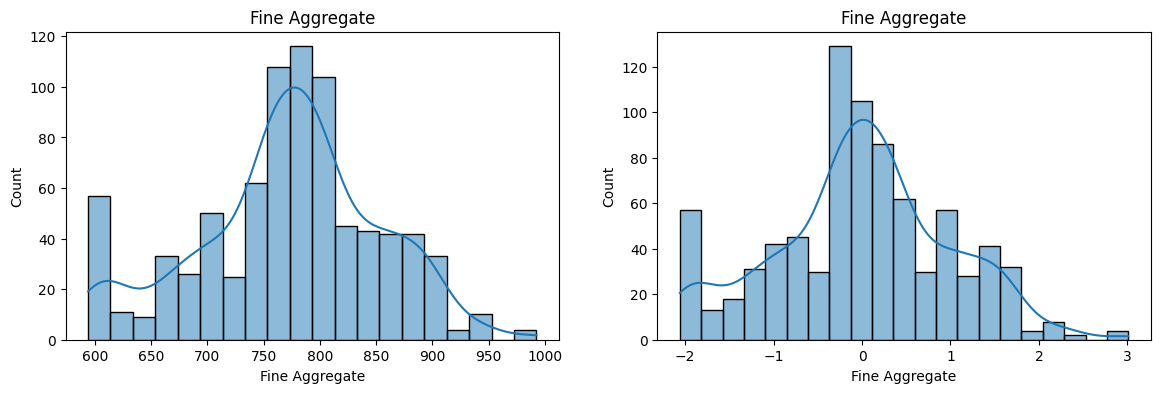

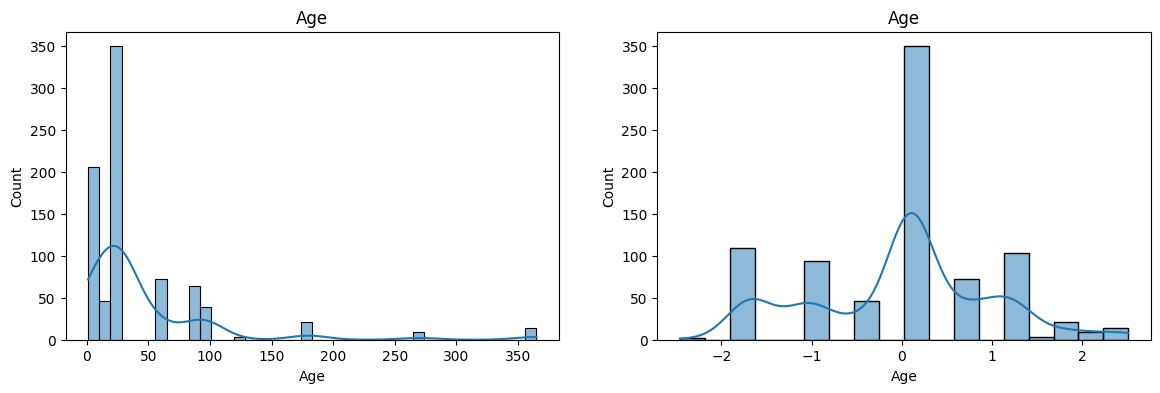

In [27]:
# Before and after comparision for Box-Cox Plot
X_train_transformed = pd.DataFrame(X_train_transformed,columns=X_train.columns)

for col in X_train_transformed.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col], kde = True)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(X_train_transformed[col], kde = True)
    plt.title(col)

    plt.show()